# 04 — VaR, CoVaR et ΔCoVaR

> **REAL / SIMULATED DATA — NOT REAL MARKET DATA.**

La VaR est affichée en unité de perte positive: $VaR_\alpha=-q_\alpha(r)$. La régression quantile estime $r_{système}=\alpha_q+\gamma_qr_{banque}+\varepsilon$ au quantile $q$. Le CoVaR de détresse évalue cette relation au quantile bancaire $q$; le CoVaR normal l'évalue à la médiane bancaire. $\Delta CoVaR=CoVaR_{détresse}-CoVaR_{médiane}$. En rendements, une valeur négative indique un rendement système de queue plus défavorable.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
from src.real_data import load_real_dataset
from src.var import historical_var, parametric_var
from src.covar import estimate_covar, leave_one_out_system_return
from src.config import REAL_LABEL

_, returns, _, _ = load_real_dataset()
rows = []
for bank in returns:
    peer_system = leave_one_out_system_return(returns, bank)
    result = estimate_covar(peer_system, returns[bank], quantile=0.05)
    rows.append({'bank_code': bank, 'historical_VaR_5pct': historical_var(returns[bank]),
                 'parametric_VaR_5pct': parametric_var(returns[bank]),
                 'CoVaR_distress': result.covar_distress, 'CoVaR_median': result.covar_normal,
                 'delta_CoVaR': result.delta_covar})
print(REAL_LABEL)
display(pd.DataFrame(rows).set_index('bank_code'))

SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA


,historical_VaR_5pct,parametric_VaR_5pct,CoVaR_distress,CoVaR_median,delta_CoVaR
bank_code,,,,,
ATW_SIM,0.018798,0.020482,-0.027533,-0.016127,-0.011406
BCP_SIM,0.022088,0.022427,-0.027651,-0.015296,-0.012355
BOA_SIM,0.023343,0.023105,-0.029046,-0.015575,-0.013471
CIH_SIM,0.026155,0.026821,-0.025769,-0.013895,-0.011874
CDM_SIM,0.026359,0.026862,-0.026222,-0.013824,-0.012398


Cette estimation est statique: elle utilise tout l'échantillon pour une estimation unique et convient à la démonstration méthodologique, pas à une prévision sans biais. Pour une analyse dynamique, une régression quantile glissante utilise seulement les observations antérieures de chaque fenêtre.

,covar_distress,covar_normal,delta_covar
date,,,
2025-09-18,-0.035610,-0.018576,-0.017034
2025-10-16,-0.035610,-0.018632,-0.016978
2025-11-13,-0.036157,-0.019626,-0.016531
2025-12-11,-0.035610,-0.019009,-0.016601
2025-12-31,-0.035610,-0.019009,-0.016601


Text(0, 0.5, 'ΔCoVaR (rendement)')

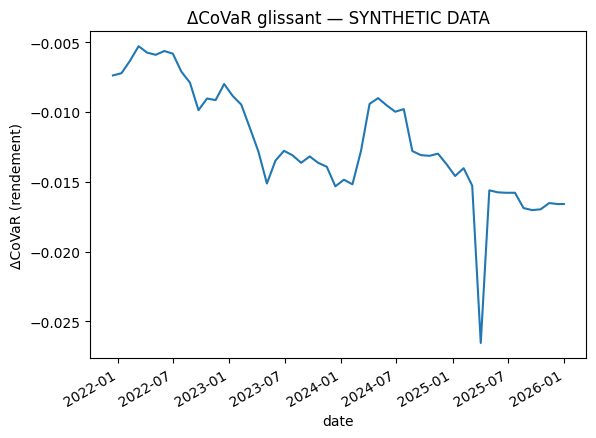

In [2]:
from src.covar import rolling_covar, leave_one_out_system_return
dynamic = rolling_covar(leave_one_out_system_return(returns, 'ATW'),
                        returns['ATW'], quantile=0.05, window=250, step=20)
display(dynamic.tail())
ax = dynamic['delta_covar'].plot(title='ΔCoVaR glissant — REAL MARKET DATA')
ax.set_ylabel('ΔCoVaR (rendement)')